In [1]:
import json
import numpy as np
import sys

import os
import pandas as pd 


In [2]:
sys.modules.pop('read_json', None)
from read_json import average_time_size, pop_time_size_stairway,pop_time_size, pop_time_size_Phlash, pop_average_time_size, pop_time_size_tskit,pop_time_size_Relate,pop_time_size_SMCpp,pop_average_sampling_time_size
sys.modules.pop('plot_code', None)
from plot_code import plot_multi_results,plot_single_results,plot_single_results_with_CI,plot_single_results_without_CI,plot_single_results_only_CI

In [3]:

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np



In [4]:
dic_color = {"Wild boar": palette[3],
"Wild boar(Europe)" : palette[3],
"Wild boar(NorthAsia)": palette[0],
"Wild boar(SouthAsia)": palette[1],
"Meishan pig": palette[6],
"Tibet pig": palette[1],
"Duroc": palette[4],
"Duroc1": palette[4],
"Duroc2": palette[4],
"Duroc3": palette[4],
"Landrace": palette[5],
"Landrace1": palette[5],
"Landrace2": palette[5],
"Landrace3": palette[5],
"Yorkshire": palette[2],
"Yorkshire1": palette[2],
"Yorkshire2": palette[2],
"Yorkshire3": palette[2],
"Yorkshire4": palette[2]}
dic_line = {"Wild boar(Europe)" : "--",
"Wild boar(NorthAsia)": "--",
"Wild boar(SouthAsia)": "--",
"Meishan pig": "-",
"Tibet pig": "-",
"Duroc1": "--",
"Duroc2": ":",
"Duroc3": "-.",
"Landrace1": "--",
"Landrace2": ":",
"Landrace3": "-.",
"Yorkshire1": ":",
"Yorkshire2": "-.",
"Yorkshire3": "--",
"Yorkshire4": (0, (1, 2,1,2,6, 2, )),}
dic_name = {"WildBoars_WildBoars": "Wild boar",
    "Meishan_Meishan": "Meishan pig",
    "WildBoars_Europe": "Wild boar(Europe)",
    "WildBoars_SouthAsian": "Wild boar(NorthAsia)",
    "WildBoars_NorthAsian": "Wild boar(SouthAsia)",
    "Tibetan_Tibet": "Tibet pig",
    "Duroc_Duroc": "Duroc",
    "Landrace_Landrace": "Landrace",
    "Yorkshire_Yorkshire": "Yorkshire",
    "Duroc_Duroc1": "Duroc1",
    "Duroc_Duroc2": "Duroc2",
    'Duroc_Duroc3': "Duroc3",
    "Landrace_Landrace1": "Landrace1",
    'Landrace_Landrace2': 'Landrace2',
    'Landrace_Landrace3': 'Landrace3',
    'Yorkshire_Yorkshire1': 'Yorkshire1',
    'Yorkshire_Yorkshire2': 'Yorkshire2',
    'Yorkshire_Yorkshire3': 'Yorkshire3',
    'Yorkshire_Yorkshire4': 'Yorkshire4',}

# PSMC

In [41]:
pop_list, average_times,average_sizes,median_sizes,all_times,all_sizes = pop_average_time_size(os.path.join("../../Ne/nf/data01","PSMC_results.json"))
dic_method_results={}

In [ ]:
pop_interest = [7,6,5,14,10,0,8,9,11,1,12,13,2,4,3]
for i in pop_interest:
    pop_name=dic_name[pop_list[i]]
    dic_method_results[pop_name]=[average_times[i],median_sizes[i],average_sizes[i],all_times[i],all_sizes[i]]
    plot_multi_results(axs, average_times[i], average_sizes[i],median_sizes[i], all_times[i], all_sizes[i],"PSMC",dic_color[pop_name],dic_color[pop_name],dic_line[pop_name],":",max_time=1e+6,label=pop_name)
dic_all_results["PSMC"]=dic_method_results

# MSMC

In [43]:
pop_list, average_times,average_sizes,median_sizes,all_times,all_sizes = pop_average_sampling_time_size(os.path.join("../../Ne/nf/data01","MSMC_results_sampling.json"))

In [ ]:
dic_method_results={}
pop_interest = [7,6,5,14,10,0,8,9,11,1,12,13,2,4,3]
for i in pop_interest:
    pop_name=dic_name[pop_list[i]]
    dic_method_results[pop_name]=[average_times[i],median_sizes[i],average_sizes[i],all_times[i],all_sizes[i]]
    plot_multi_results(axs, average_times[i], average_sizes[i],median_sizes[i], all_times[i], all_sizes[i],"MSMC",dic_color[pop_name],dic_color[pop_name],dic_line[pop_name],":",max_time=1e+6,label=pop_name)
dic_all_results["MSMC2"]=dic_method_results

# SMC++

In [ ]:
pop_list, times, sizes = pop_time_size_SMCpp(os.path.join("../../Ne/nf/data01","SMCpp_results.json"))
dic_method_results={}
pop_interest = [7,6,5,14,10,0,8,9,11,1,12,13,2,4,3]
for i in pop_interest:
    pop_name=dic_name[pop_list[i][:-8]]
    dic_method_results[pop_name]=[times[i], sizes[i]]
    plot_single_results(axs, times[i], sizes[i], pop_name, dic_color[pop_name],dic_line[pop_name],max_time=1e+7)
dic_all_results["SMC++"]=dic_method_results

# PHALSH

In [ ]:
pop_list, times, sizes = pop_time_size_Phlash(os.path.join("../../Ne/phlash_results","Phlash_results.json"))
fig,axs = plt.subplots(figsize=(10, 6))
dic_method_results={}
pop_interest = [7,6,5,14,10,0,8,9,11,1,12,13,2,4,3]
# pop_interest = [7,6,5]
for i in pop_interest:
    pop_name=dic_name[pop_list[i]]
    dic_method_results[pop_name]=[times[i], sizes[i][0],sizes[i]]
dic_all_results["PHLASH"]=dic_method_results

# GONE

In [ ]:
pop_list, times, sizes = pop_time_size(os.path.join("../../Ne/nf/data01/","GONE_results.json"))
dic_method_results={}
# 15,11
pop_interest = [7,0,5,16,13,2,9,12,10,6,1,4,8,14,3]
for i in pop_interest:
    pop_name=dic_name[pop_list[i][10:]]
    dic_method_results[pop_name]=[times[i], sizes[i]]
dic_all_results["GONe"]=dic_method_results

# Relate

In [ ]:
pop_list, times, sizes = pop_time_size_Relate(os.path.join("../../Ne/nf/data01/","Relate_results.json"))
pop_interest = [7,0,5,16,13,2,9,12,10,6,1,4,8,14,3]
dic_method_results={}
for pop_index in pop_interest:
    pop_name=dic_name[pop_list[pop_index]]
    dic_method_results[pop_name]=[times[pop_index], sizes[pop_index]]
dic_all_results["Relate"]=dic_method_results

# Tskit

In [ ]:
pop_list, times, sizes = pop_time_size_tskit(os.path.join("../../Ne/nf/data01/","tskit_results.json"))
dic_method_results={}
pop_interest = [7,6,5,14,10,0,8,9,11,1,12,13,2,4,3]
# pop_interest = [23,7,6,5]
for pop_index in pop_interest:
    pop_name=dic_name[pop_list[pop_index]]
    dic_method_results[pop_name]=[times[pop_index], sizes[pop_index]]
dic_all_results["tsinfer & tsdate"]=dic_method_results

# stairway

In [ ]:
pop_list, times, sizes = pop_time_size_stairway(os.path.join("../../Ne/nf/data01/","stairway_results.json"))

dic_method_results={}
pop_interest = [12,7,4,15,3,14,5,0,2,16,8,10,11,13,1,9]
for i in pop_interest:
    pop_name=dic_name[pop_list[i].split(".")[0][9:]]
    print(pop_name)
    dic_method_results[pop_name]=[times[i], sizes[i][0],sizes[i]]
dic_all_results["Stairway plot V2"]=dic_method_results

# Total 

In [25]:
dic_name

{'WildBoars_WildBoars': 'Wild boar',
 'Meishan_Meishan': 'Meishan pig',
 'WildBoars_Europe': 'Wild boar(Europe)',
 'WildBoars_SouthAsian': 'Wild boar(NorthAsia)',
 'WildBoars_NorthAsian': 'Wild boar(SouthAsia)',
 'Tibetan_Tibet': 'Tibet pig',
 'Duroc_Duroc': 'Duroc',
 'Landrace_Landrace': 'Landrace',
 'Yorkshire_Yorkshire': 'Yorkshire',
 'Duroc_Duroc1': 'Duroc1',
 'Duroc_Duroc2': 'Duroc2',
 'Duroc_Duroc3': 'Duroc3',
 'Landrace_Landrace1': 'Landrace1',
 'Landrace_Landrace2': 'Landrace2',
 'Landrace_Landrace3': 'Landrace3',
 'Yorkshire_Yorkshire1': 'Yorkshire1',
 'Yorkshire_Yorkshire2': 'Yorkshire2',
 'Yorkshire_Yorkshire3': 'Yorkshire3',
 'Yorkshire_Yorkshire4': 'Yorkshire4',
 'WannanBlack_WannanBlack': 'WannanBlack pig',
 'AnqingSixendwhite_AnqingSixendwhite': 'AnqingSixendwhite pig',
 'Europe_Europe': 'Wild boar(Europe)',
 'NorthAsian_NorthAsian': 'Wild boar(NorthAsia)',
 'SouthAsian_SouthAsian': 'Wild boar(SouthAsia)',
 'Tibet_Tibet': 'Tibet pig',
 'Duroc1_Duroc1': 'Duroc1',
 'Duroc2

In [39]:
dic_method_line={
'PSMC': "-",
'MSMC2': "-",
'SMC++': "-",
'PHLASH': "-",
'tsinfer & tsdate':"--",
'Relate': "--",
'GONe': "-.",
'Stairway plot V2': "-."
}
dic_method_color={
'PSMC': palette[0],
'MSMC2': palette[1],
'SMC++': palette[2],
'PHLASH': palette[3],
'tsinfer & tsdate':palette[4],
'Relate': palette[5],
'GONe': palette[6],
'Stairway plot V2': palette[7]
}

In [40]:
pop = [["Wild boar(Europe)",'Wild boar(NorthAsia)','Wild boar(SouthAsia)'], 
['Duroc1','Duroc2','Duroc3'],
['Landrace1','Landrace2','Landrace3'],
['Yorkshire1','Yorkshire2','Yorkshire3'],
['Yorkshire4','Meishan pig','Tibet pig']]
methods=['PSMC', 'MSMC2', 'SMC++', 'PHLASH', 'tsinfer & tsdate', 'Relate', 'GONe', 'Stairway plot V2']

Index max time: 64
Index max time: 32
Index max time: 101
Index max time: 88
Index max time: 64
Index max time: 19
Index max time: 755
Index max time: 2002
Wild boar
(Europe)
Index max time: 64
Index max time: 32
Index max time: 101
Index max time: 87
Index max time: 64
Index max time: 19
Index max time: 791
Index max time: 962
Wild boar
(NorthAsia)
Index max time: 64
Index max time: 32
Index max time: 101
Index max time: 87
Index max time: 64
Index max time: 19
Index max time: 791
Index max time: 962
Wild boar
(SouthAsia)
Index max time: 91
Index max time: 64
Index max time: 19
Index max time: 755
Index max time: 12002
Index max time: 84
Index max time: 64
Index max time: 19
Index max time: 791
Index max time: 12242
Index max time: 88
Index max time: 64
Index max time: 19
Index max time: 791
Index max time: 7762
Index max time: 87
Index max time: 64
Index max time: 19
Index max time: 755
Index max time: 2882
Index max time: 88
Index max time: 64
Index max time: 19
Index max time: 791


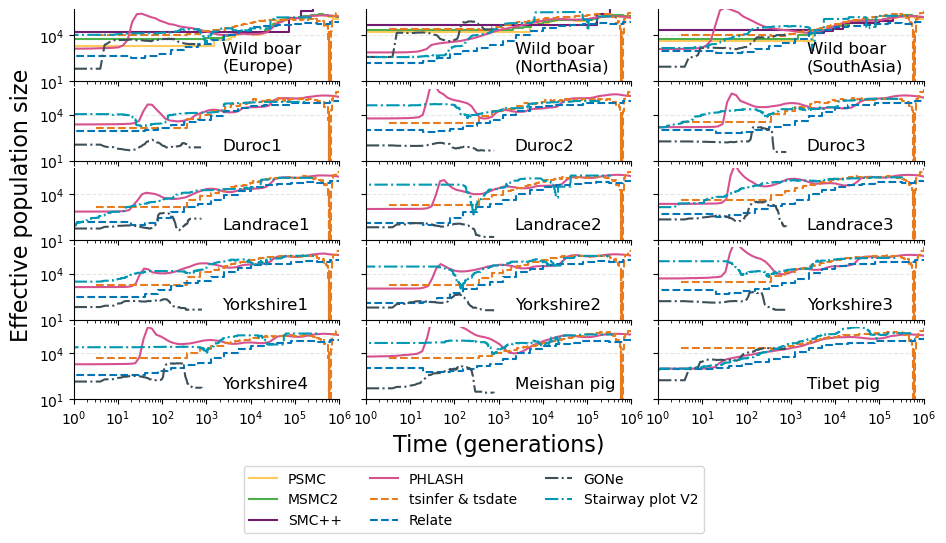

In [57]:
import matplotlib.gridspec as gridspec
fig,axs = plt.subplots(5,3,figsize=(10, 6))

for r in range(5):
    for c in range(3):
        ax = axs[r, c]
        pop_name = pop[r][c]

        for method in methods:
            try:
                value = dic_all_results[method][pop_name]
                plot_single_results(
                    ax,
                    value[0], value[1],
                    method,
                    dic_method_color[method],
                    dic_method_line[method],
                    max_time=1e7
                )
            except KeyError:
                continue
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlim(1, 1e6)
        ax.set_ylim(10, 5e5)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.grid(axis='y', alpha=0.3, linestyle='--')
        if "(" in pop_name:
            pop_name=pop_name.replace("(","\n(",)
            print(pop_name)
        ax.text(0.56, 0.15, pop_name,
        transform=ax.transAxes,
        fontsize=12, )

for ax in axs[:, 1:].flat:
    ax.tick_params(axis="y", labelleft=False)

for ax in axs[:-1, :].flat:
    ax.tick_params(axis="x", labelbottom=False)

handles, labels = axs[0, 0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    bbox_to_anchor=(0.5, 0.15),
    loc="upper center",
    ncol=3
)

axs[-1,1].set_xlabel("Time (generations)",fontsize=16)
axs[2, 0].set_ylabel("Effective population size",fontsize=16)

plt.subplots_adjust(
    left=0.1,      # left
    right=0.95,    # right
    top=0.90,      # top
    bottom=0.25,    # botton
    hspace=0.1,    # Vertical 
    wspace=0.1     # Horizon 
)
# axs.legend(bbox_to_anchor=(0.5, -0.1), loc='upper center', ncol=2)
plt.savefig("../Figure/Realdata.png",dpi=300)


Index max time: 64
Index max time: 32
Index max time: 101
Index max time: 88
Index max time: 64
Index max time: 19
Index max time: 2002
Wild boar
(Europe)
Index max time: 64
Index max time: 32
Index max time: 101
Index max time: 87
Index max time: 64
Index max time: 19
Index max time: 962
Wild boar
(NorthAsia)
Index max time: 64
Index max time: 32
Index max time: 101
Index max time: 87
Index max time: 64
Index max time: 19
Index max time: 962
Wild boar
(SouthAsia)


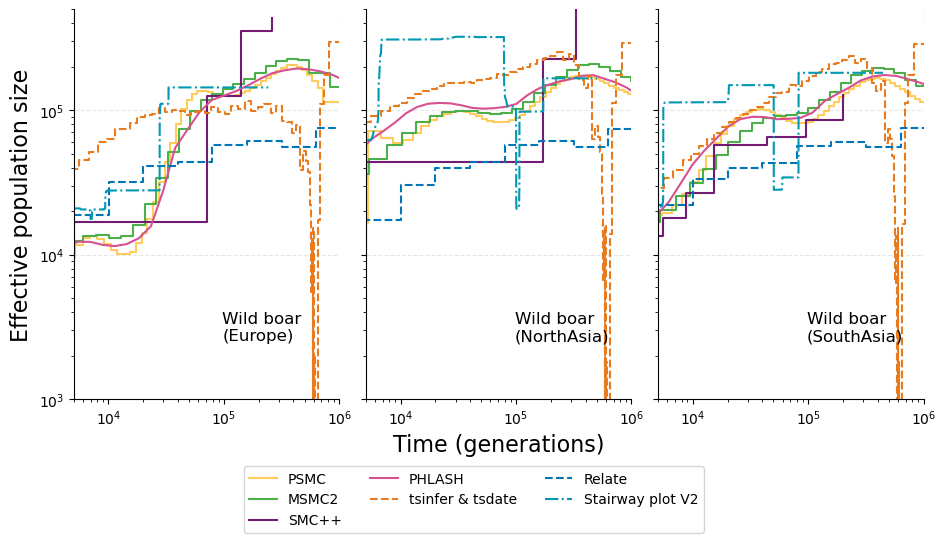

In [58]:
pop = ["Wild boar(Europe)",'Wild boar(NorthAsia)','Wild boar(SouthAsia)']
methods=['PSMC', 'MSMC2', 'SMC++', 'PHLASH', 'tsinfer & tsdate', 'Relate', 'Stairway plot V2']
import matplotlib.gridspec as gridspec
fig,axs = plt.subplots(1,3,figsize=(10, 6),sharey=True)


for c in range(3):
    ax = axs[c]
    pop_name = pop[c]

    for method in methods:
        try:
            value = dic_all_results[method][pop_name]
            plot_single_results(
                ax,
                value[0], value[1],
                method,
                dic_method_color[method],
                dic_method_line[method],
                max_time=1e7
            )
        except KeyError:
            continue
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(5e3, 1e6)
    ax.set_ylim(1000, 5e5)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(axis='y', alpha=0.3, linestyle='--')
    if "(" in pop_name:
        pop_name=pop_name.replace("(","\n(",)
        print(pop_name)
    ax.text(0.56, 0.15, pop_name,
    transform=ax.transAxes,
    fontsize=12, )

handles, labels = axs[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    bbox_to_anchor=(0.5, 0.15),
    loc="upper center",
    ncol=3
)

axs[1].set_xlabel("Time (generations)",fontsize=16)
axs[0].set_ylabel("Effective population size",fontsize=16)

plt.subplots_adjust(
    left=0.1,      # left
    right=0.95,    # right
    top=0.90,      # top
    bottom=0.25,    # botton
    hspace=0.1,    # Vertical 
    wspace=0.1     # Horizon 
)
# axs.legend(bbox_to_anchor=(0.5, -0.1), loc='upper center', ncol=2)
plt.savefig("../Figure/Realdata_wildboar_ancient_epoch.png",dpi=300)


In [59]:
sys.modules.pop('root_mean_squared_error', None)
from root_mean_squared_error import interp_timepoint,interp_timeperiod

def fun_time_sizes(pop_name,methods,dic_all_results,t_grid):
    li= []
    for method in methods:
        value = dic_all_results[method][pop_name]
        times = value[0] 
        sizes = value[1]
        if (times[0] == 0) or (times[0] == "0"): # Time-period
            time_lower = times[:-1]
            time_upper = times[1:]
            Ne_size = sizes[:-1]
            f_time = interp_timeperiod(time_lower, time_upper, Ne_size)
        else: # time point
            f_time = interp_timepoint(np.array(times), np.array(sizes))

        li.append(f_time(t_grid))
    arr = np.array(li)
    median = []
    for col in arr.T:   # transpose → iterate over columns
        median.append(np.nanmedian(col))
    return median

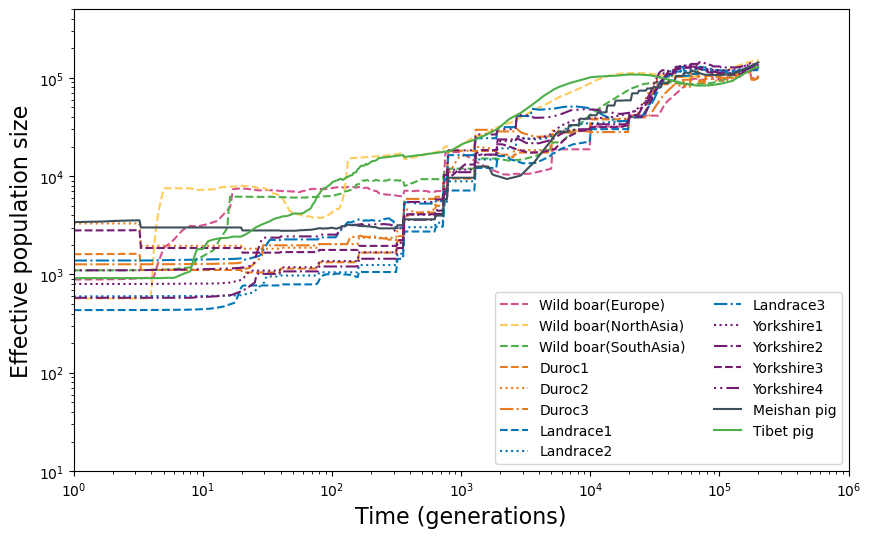

In [60]:
# methods=['PHLASH',  'Relate', 'GONe', 'Stairway plot V2','tsinfer & tsdate']
# I remove stairway because of large fluctuations 
methods=['PHLASH',  'Relate', 'GONe', 'tsinfer & tsdate']
# methods=['PHLASH',  'Relate', 'GONe']

fig,axs = plt.subplots(figsize=(10, 6))
t_grid = np.geomspace(1, 2e+5, 500)
pop = ["Wild boar(Europe)",'Wild boar(NorthAsia)','Wild boar(SouthAsia)',
'Duroc1','Duroc2','Duroc3',
'Landrace1','Landrace2','Landrace3',
'Yorkshire1','Yorkshire2','Yorkshire3',
'Yorkshire4','Meishan pig','Tibet pig']
for pop_name in pop:
    synthetical = fun_time_sizes(pop_name,methods,dic_all_results,t_grid)
    axs.plot(
    t_grid,
    synthetical,
    label=pop_name,
    color=dic_color[pop_name],
    linestyle=dic_line[pop_name]
    )
axs.set_xscale("log")
axs.set_yscale("log")
axs.set_xlim(1, 1e6)
axs.set_ylim(10, 5e5)
axs.legend(ncol=2)
axs.set_xlabel("Time (generations)",fontsize=16)
axs.set_ylabel("Effective population size",fontsize=16)
plt.savefig("../Figure/Synthetic_realdata.png",dpi=300)


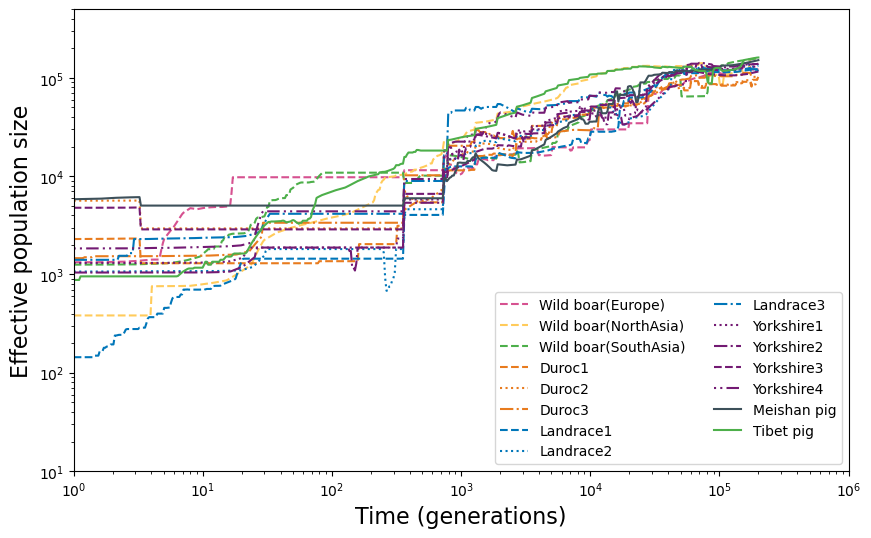

In [62]:
methods=['PHLASH',  'Relate', 'GONe', 'Stairway plot V2','tsinfer & tsdate']
# I remove stairway because of large fluctuations 
# methods=['PHLASH',  'Relate', 'GONe', 'tsinfer & tsdate']
# methods=['PHLASH',  'Relate', 'GONe']

fig,axs = plt.subplots(figsize=(10, 6))
t_grid = np.geomspace(1, 2e+5, 500)
pop = ["Wild boar(Europe)",'Wild boar(NorthAsia)','Wild boar(SouthAsia)',
'Duroc1','Duroc2','Duroc3',
'Landrace1','Landrace2','Landrace3',
'Yorkshire1','Yorkshire2','Yorkshire3',
'Yorkshire4','Meishan pig','Tibet pig']
for pop_name in pop:
    synthetical = fun_time_sizes(pop_name,methods,dic_all_results,t_grid)
    axs.plot(
    t_grid,
    synthetical,
    label=pop_name,
    color=dic_color[pop_name],
    linestyle=dic_line[pop_name]
    )
axs.set_xscale("log")
axs.set_yscale("log")
axs.set_xlim(1, 1e6)
axs.set_ylim(10, 5e5)
axs.legend(ncol=2)
axs.set_xlabel("Time (generations)",fontsize=16)
axs.set_ylabel("Effective population size",fontsize=16)
plt.savefig("../Figure/Synthetic_realdata_5methods.png",dpi=300)

/var/folders/sq/vc6_dvd116b6pt9nrzq_m1100000gr/T/ipykernel_79696/2236849274.py:22: RuntimeWarning: All-NaN slice encountered
  median.append(np.nanmedian(col))


Text(0, 0.5, 'Effective population size')

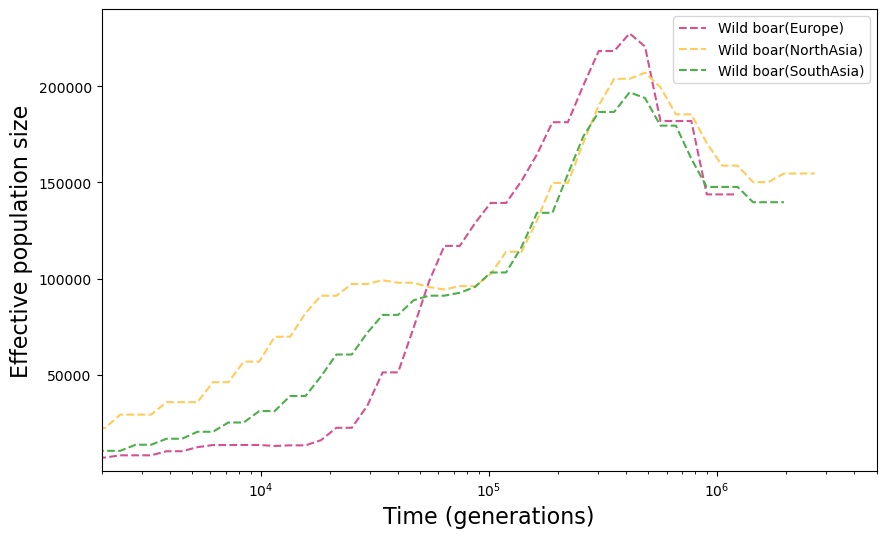

In [61]:
fig,axs = plt.subplots(figsize=(10, 6))
t_grid = np.geomspace(1, 5e+6, 100)
pop = ["Wild boar(Europe)",'Wild boar(NorthAsia)','Wild boar(SouthAsia)',]
# methods=['PHLASH',  'Relate', 'PSMC','MSMC2']
methods=['MSMC2']

for pop_name in pop:
    synthetical = fun_time_sizes(pop_name,methods,dic_all_results,t_grid)
    axs.plot(
    t_grid,
    synthetical,
    label=pop_name,
    color=dic_color[pop_name],
    linestyle=dic_line[pop_name]
    )
axs.set_xscale("log")
# axs.set_yscale("log")
axs.set_xlim(2e3, 5e6)
axs.set_ylim(1, 2.4e5)
axs.legend()
axs.set_xlabel("Time (generations)",fontsize=16)
axs.set_ylabel("Effective population size",fontsize=16)
# plt.savefig("../Figure/Synthetic_realdata_aa.png",dpi=300)